# Pouvoir d’achat en unités du sous-panier couvert

Ce notebook réutilise les exports validés du notebook 04 pour les 18 profils ENNVM 2022–2023. Il conserve les périmètres prudent (groupes 01, 03, 05 et 10) et élargi (01 à 11 et 13). C1 à C5 sont des quintiles de **dépense annuelle par personne**, définis dans chaque milieu. Les profils « Total » désignent les ensembles national, urbain et rural.

## 1. Hypothèses et définition

La croissance nominale hypothétique des ressources $g_R$ prend quatre valeurs : 0 %, +3 %, +5 % et +10 %. On suppose que le montant affecté à l’achat du sous-panier évolue à ce même taux. Les ressources, leur évolution et leur affectation sont des hypothèses, distinctes des données du HCP. La composition du sous-panier reste fixe.

Si $R_0$ et $C_0$ désignent les ressources affectées et le coût initial du sous-panier, les ressources de comparaison valent $R_0(1+g_R)$ et son coût $C_0(1+\pi_h)$. Le nombre de sous-paniers accessibles est le rapport ressources sur coût. Sa variation relative vaut :

$$
\Delta_{\mathrm{PA}}=\frac{1+g_R}{1+\pi_h}-1.
$$

Une valeur négative signifie que les ressources hypothétiques achètent moins d’unités du sous-panier. Le seuil d’équilibre est $g_R=\pi_h$. Si le coût baisse, ce seuil est négatif : une baisse nominale de même proportion maintiendrait exactement le nombre d’unités accessibles. On conserve ce seuil signé.

Les trajectoires à prix historiques utilisent le coût simulé du notebook 04, avec septembre 2022 comme référence commune. Chaque taux nominal est une variation **totale** entre cette référence et la date considérée. Il ne s’agit ni d’un taux annuel ni d’une trajectoire de revenu cumulée mois après mois. Les dates antérieures à septembre 2022 donnent des comparaisons rétrospectives avec cette même référence. Dans les chocs hypothétiques, les quatre taux nominaux s’appliquent une seule fois entre l’avant et l’après-choc.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

racine = Path.cwd()
if racine.name == "notebooks":
    racine = racine.parent
sorties = racine / "outputs"
historique = pd.read_csv(sorties / "04_cout_panier_historique.csv", parse_dates=["date"])
chocs = pd.read_csv(sorties / "04_chocs_hypothetiques.csv")
profils = pd.read_csv(racine / "data" / "processed" / "profils_budgetaires_2022_2023.csv")

perimetres = ["prudent", "elargi"]
milieux = ["National", "Urbain", "Rural"]
classes = ["C1", "C2", "C3", "C4", "C5", "Total"]
ordre = [f"{m}_{c}" for m in milieux for c in classes]
noms_profils = [f"{m} · {c if c != 'Total' else 'Ensemble'}" for m in milieux for c in classes]
hypotheses = [0, 3, 5, 10]
reference = pd.Timestamp("2022-09-01")
dates = pd.date_range("2017-01-01", "2026-10-01", freq="MS")
noms_chocs = {
    "uniforme_5pct": "Hausse uniforme de 5 %",
    "uniforme_5pct_puis_alimentaire_10pct": "Hausse uniforme puis choc alimentaire",
}
cout_hist = "variation_depuis_sept_2022_pct"
cout_choc = "variation_cout_sous_panier_pct"
indice = "indice_cout_sous_panier_base_100_sept_2022"
couverture = "couverture_budget_pct"

# Vérifier les clés attendues pour que chaque profil soit comparable.
def verifier_cles(table, colonnes, valeurs):
    attendues = pd.MultiIndex.from_product(valeurs, names=colonnes)
    observees = pd.MultiIndex.from_frame(table[colonnes])
    if not observees.is_unique or not observees.sort_values().equals(attendues.sort_values()):
        raise ValueError(f"Clés manquantes, inattendues ou dupliquées : {colonnes}.")

verifier_cles(profils, ["milieu", "classe_depense"], [milieux, classes])
if not profils["profil"].eq(profils["milieu"] + "_" + profils["classe_depense"]).all():
    raise ValueError("Les identifiants des profils ne concordent pas avec le milieu et la classe.")
verifier_cles(historique, ["date", "perimetre", "profil"], [dates, perimetres, ordre])
verifier_cles(chocs, ["choc_hypothetique", "perimetre", "profil"], [noms_chocs, perimetres, ordre])

# Écarter toute valeur qui rendrait le rapport économique indéfini.
for table, colonne in [(historique, cout_hist), (chocs, cout_choc)]:
    valeurs = table[[colonne, couverture]].to_numpy(dtype=float)
    if not np.isfinite(valeurs).all() or not table[colonne].gt(-100).all():
        raise ValueError("Les coûts doivent rester finis et strictement positifs après variation.")
    if not table[couverture].gt(0).all() or not table[couverture].le(100).all():
        raise ValueError("La couverture doit être supérieure à 0 % et au plus égale à 100 %.")

paires = ["perimetre", "profil"]
couvertures = historique.loc[historique["date"].eq(reference)].set_index(paires)[couverture]
for table in (historique, chocs):
    np.testing.assert_allclose(table[couverture], table.set_index(paires).index.map(couvertures))
np.testing.assert_allclose(historique[indice] - 100, historique[cout_hist], atol=1e-8, rtol=0)
np.testing.assert_allclose(historique.loc[historique["date"].eq(reference), indice], 100)
np.testing.assert_allclose(chocs.loc[chocs["choc_hypothetique"].eq("uniforme_5pct"), cout_choc], 5)
print(f"Exports vérifiés : {len(historique):,} lignes historiques, {len(chocs)} chocs par profil et périmètre.")

Exports vérifiés : 4,248 lignes historiques, 72 chocs par profil et périmètre.


## 2. Calcul et seuil d’équilibre

Les entrées et sorties tabulaires sont en pourcentage. Le calcul convertit les taux en fractions, puis exprime la variation du nombre d’unités accessibles en pourcentage. La colonne de seuil répète le taux de coût pour rendre immédiatement visible la croissance nominale qui neutraliserait ce coût. La couverture budgétaire est conservée à titre descriptif. Elle ne multiplie pas le taux de pouvoir d’achat du sous-panier.

In [2]:
revenu = "croissance_nominale_hypothetique_pct"
variation = "variation_pouvoir_achat_sous_panier_pct"
seuil = "croissance_nominale_equilibre_pct"


def pouvoir_achat_pct(croissance_pct, cout_pct):
    """Calculer la variation du nombre d’unités accessibles, en pourcentage."""
    return 100 * ((1 + croissance_pct / 100) / (1 + cout_pct / 100) - 1)


def calculer_scenarios(table, colonnes, colonne_cout):
    """Associer chaque prix comparé aux quatre hypothèses nominales."""
    resultat = table[colonnes + paires + [couverture, colonne_cout]].rename(
        columns={colonne_cout: "variation_cout_sous_panier_pct"}
    )
    resultat = resultat.merge(profils[["profil", "milieu", "classe_depense"]],
                              on="profil", validate="many_to_one")
    resultat = resultat.merge(pd.DataFrame({revenu: hypotheses}), how="cross")
    resultat[seuil] = resultat["variation_cout_sous_panier_pct"]
    resultat[variation] = pouvoir_achat_pct(resultat[revenu], resultat[seuil])

    # Le seuil annule exactement la variation et le signe suit l’écart revenu-coût.
    np.testing.assert_allclose(pouvoir_achat_pct(resultat[seuil], resultat[seuil]), 0, atol=1e-12)
    ecart = resultat[revenu] - resultat[seuil]
    np.testing.assert_allclose(resultat[variation], ecart / (1 + resultat[seuil] / 100), atol=1e-10)
    assert np.isfinite(resultat[variation]).all()
    assert resultat.groupby(colonnes + paires)[variation].diff().dropna().gt(0).all()
    return resultat


resultats_hist = calculer_scenarios(historique, ["date"], cout_hist)
resultats_chocs = calculer_scenarios(chocs, ["choc_hypothetique"], cout_choc)
assert len(resultats_hist) == 118 * 18 * 2 * 4
assert len(resultats_chocs) == 2 * 18 * 2 * 4
a_reference = resultats_hist["date"].eq(reference)
np.testing.assert_allclose(resultats_hist.loc[a_reference, variation],
                           resultats_hist.loc[a_reference, revenu], atol=1e-10)
neutralite = resultats_chocs["choc_hypothetique"].eq("uniforme_5pct") & resultats_chocs[revenu].eq(5)
assert neutralite.sum() == 36
np.testing.assert_allclose(resultats_chocs.loc[neutralite, variation], 0, atol=1e-12)
print("Contrôles réussis : seuil, référence, choc uniforme, signe et ordre des hypothèses.")

Contrôles réussis : seuil, référence, choc uniforme, signe et ordre des hypothèses.


## 3. Comparaisons par périmètre, milieu et quintile

Le tableau à la dernière date historique compare octobre 2026 à septembre 2022. Les tableaux des chocs présentent l’effet après le choc uniforme de 5 %, puis après la hausse uniforme suivie d’une hausse supplémentaire de 10 % du prix alimentaire déjà majoré. Dans ce second cas, la hausse totale du prix du groupe alimentaire est de 15,5 %. Chaque ligne indique la couverture et le seuil d’équilibre. Les quatre dernières colonnes présentent les variations du pouvoir d’achat du sous-panier.

In [3]:
def grille(table):
    return table.pivot(index="profil", columns=revenu, values=variation).reindex(ordre)[hypotheses]


def montrer_table(table):
    meta = table.drop_duplicates("profil").set_index("profil")[[couverture, seuil]].reindex(ordre)
    meta.columns = ["Couverture (%)", "Seuil nominal (%)"]
    resume = meta.join(grille(table).rename(columns={g: f"Ressources +{g} %" for g in hypotheses}))
    resume.index = noms_profils
    display(resume.round(2))


dernier_mois = dates[-1]
dernier = resultats_hist.loc[resultats_hist["date"].eq(dernier_mois)]
for perimetre in perimetres:
    display(Markdown(f"**Octobre 2026 / septembre 2022 · {perimetre}**"))
    montrer_table(dernier.loc[dernier["perimetre"].eq(perimetre)])
    for choc, nom in noms_chocs.items():
        display(Markdown(f"**{nom} · {perimetre}**"))
        montrer_table(resultats_chocs.loc[
            resultats_chocs["perimetre"].eq(perimetre) & resultats_chocs["choc_hypothetique"].eq(choc)
        ])

**Octobre 2026 / septembre 2022 · prudent**

,Couverture (%),Seuil nominal (%),Ressources +0 %,Ressources +3 %,Ressources +5 %,Ressources +10 %
National · C1,51.9,9.42,-8.61,-5.87,-4.04,0.53
National · C2,48.8,9.38,-8.58,-5.83,-4.01,0.57
National · C3,46.2,9.36,-8.56,-5.81,-3.99,0.59
National · C4,43.0,9.31,-8.52,-5.77,-3.94,0.63
National · C5,36.1,9.04,-8.29,-5.54,-3.71,0.88
National · Ensemble,41.4,9.22,-8.44,-5.70,-3.86,0.71
Urbain · C1,45.0,9.39,-8.59,-5.84,-4.01,0.56
Urbain · C2,43.5,9.35,-8.55,-5.80,-3.97,0.60
Urbain · C3,42.3,9.31,-8.52,-5.77,-3.94,0.63
Urbain · C4,40.4,9.26,-8.48,-5.73,-3.90,0.67


**Hausse uniforme de 5 % · prudent**

,Couverture (%),Seuil nominal (%),Ressources +0 %,Ressources +3 %,Ressources +5 %,Ressources +10 %
National · C1,51.9,5.0,-4.76,-1.9,0.0,4.76
National · C2,48.8,5.0,-4.76,-1.9,0.0,4.76
National · C3,46.2,5.0,-4.76,-1.9,0.0,4.76
National · C4,43.0,5.0,-4.76,-1.9,0.0,4.76
National · C5,36.1,5.0,-4.76,-1.9,0.0,4.76
National · Ensemble,41.4,5.0,-4.76,-1.9,0.0,4.76
Urbain · C1,45.0,5.0,-4.76,-1.9,0.0,4.76
Urbain · C2,43.5,5.0,-4.76,-1.9,0.0,4.76
Urbain · C3,42.3,5.0,-4.76,-1.9,0.0,4.76
Urbain · C4,40.4,5.0,-4.76,-1.9,0.0,4.76


**Hausse uniforme puis choc alimentaire · prudent**

,Couverture (%),Seuil nominal (%),Ressources +0 %,Ressources +3 %,Ressources +5 %,Ressources +10 %
National · C1,51.9,14.31,-12.52,-9.89,-8.14,-3.77
National · C2,48.8,14.17,-12.41,-9.78,-8.03,-3.65
National · C3,46.2,14.00,-12.28,-9.65,-7.89,-3.51
National · C4,43.0,13.79,-12.12,-9.48,-7.73,-3.33
National · C5,36.1,12.77,-11.32,-8.66,-6.89,-2.45
National · Ensemble,41.4,13.47,-11.87,-9.23,-7.47,-3.06
Urbain · C1,45.0,14.12,-12.38,-9.75,-7.99,-3.61
Urbain · C2,43.5,13.91,-12.21,-9.58,-7.82,-3.43
Urbain · C3,42.3,13.74,-12.08,-9.44,-7.68,-3.29
Urbain · C4,40.4,13.47,-11.87,-9.23,-7.47,-3.06


... (2 outputs left out)

**Hausse uniforme de 5 % · elargi**

,Couverture (%),Seuil nominal (%),Ressources +0 %,Ressources +3 %,Ressources +5 %,Ressources +10 %
National · C1,98.0,5.0,-4.76,-1.9,0.0,4.76
National · C2,97.1,5.0,-4.76,-1.9,0.0,4.76
National · C3,95.9,5.0,-4.76,-1.9,0.0,4.76
National · C4,94.5,5.0,-4.76,-1.9,0.0,4.76
National · C5,90.1,5.0,-4.76,-1.9,0.0,4.76
National · Ensemble,93.2,5.0,-4.76,-1.9,0.0,4.76
Urbain · C1,97.7,5.0,-4.76,-1.9,0.0,4.76
Urbain · C2,96.2,5.0,-4.76,-1.9,0.0,4.76
Urbain · C3,95.1,5.0,-4.76,-1.9,0.0,4.76
Urbain · C4,93.4,5.0,-4.76,-1.9,0.0,4.76


**Hausse uniforme puis choc alimentaire · elargi**

,Couverture (%),Seuil nominal (%),Ressources +0 %,Ressources +3 %,Ressources +5 %,Ressources +10 %
National · C1,98.0,9.93,-9.03,-6.30,-4.48,0.06
National · C2,97.1,9.61,-8.76,-6.03,-4.20,0.36
National · C3,95.9,9.34,-8.54,-5.79,-3.97,0.61
National · C4,94.5,9.00,-8.26,-5.50,-3.67,0.92
National · C5,90.1,8.11,-7.50,-4.73,-2.88,1.75
National · Ensemble,93.2,8.76,-8.06,-5.30,-3.46,1.14
Urbain · C1,97.7,9.20,-8.43,-5.68,-3.85,0.73
Urbain · C2,96.2,9.03,-8.28,-5.53,-3.69,0.89
Urbain · C3,95.1,8.89,-8.16,-5.41,-3.57,1.02
Urbain · C4,93.4,8.66,-7.97,-5.21,-3.37,1.23


## 4. Exports et figures

Les deux CSV contiennent les quatre taux de ressources, la couverture, le taux de coût, le seuil nominal et la variation du pouvoir d’achat du sous-panier. La matrice historique affiche le dernier mois du fichier. Les matrices des chocs utilisent la même échelle de couleur entre périmètres. Chaque cellule est annotée en pourcentage.

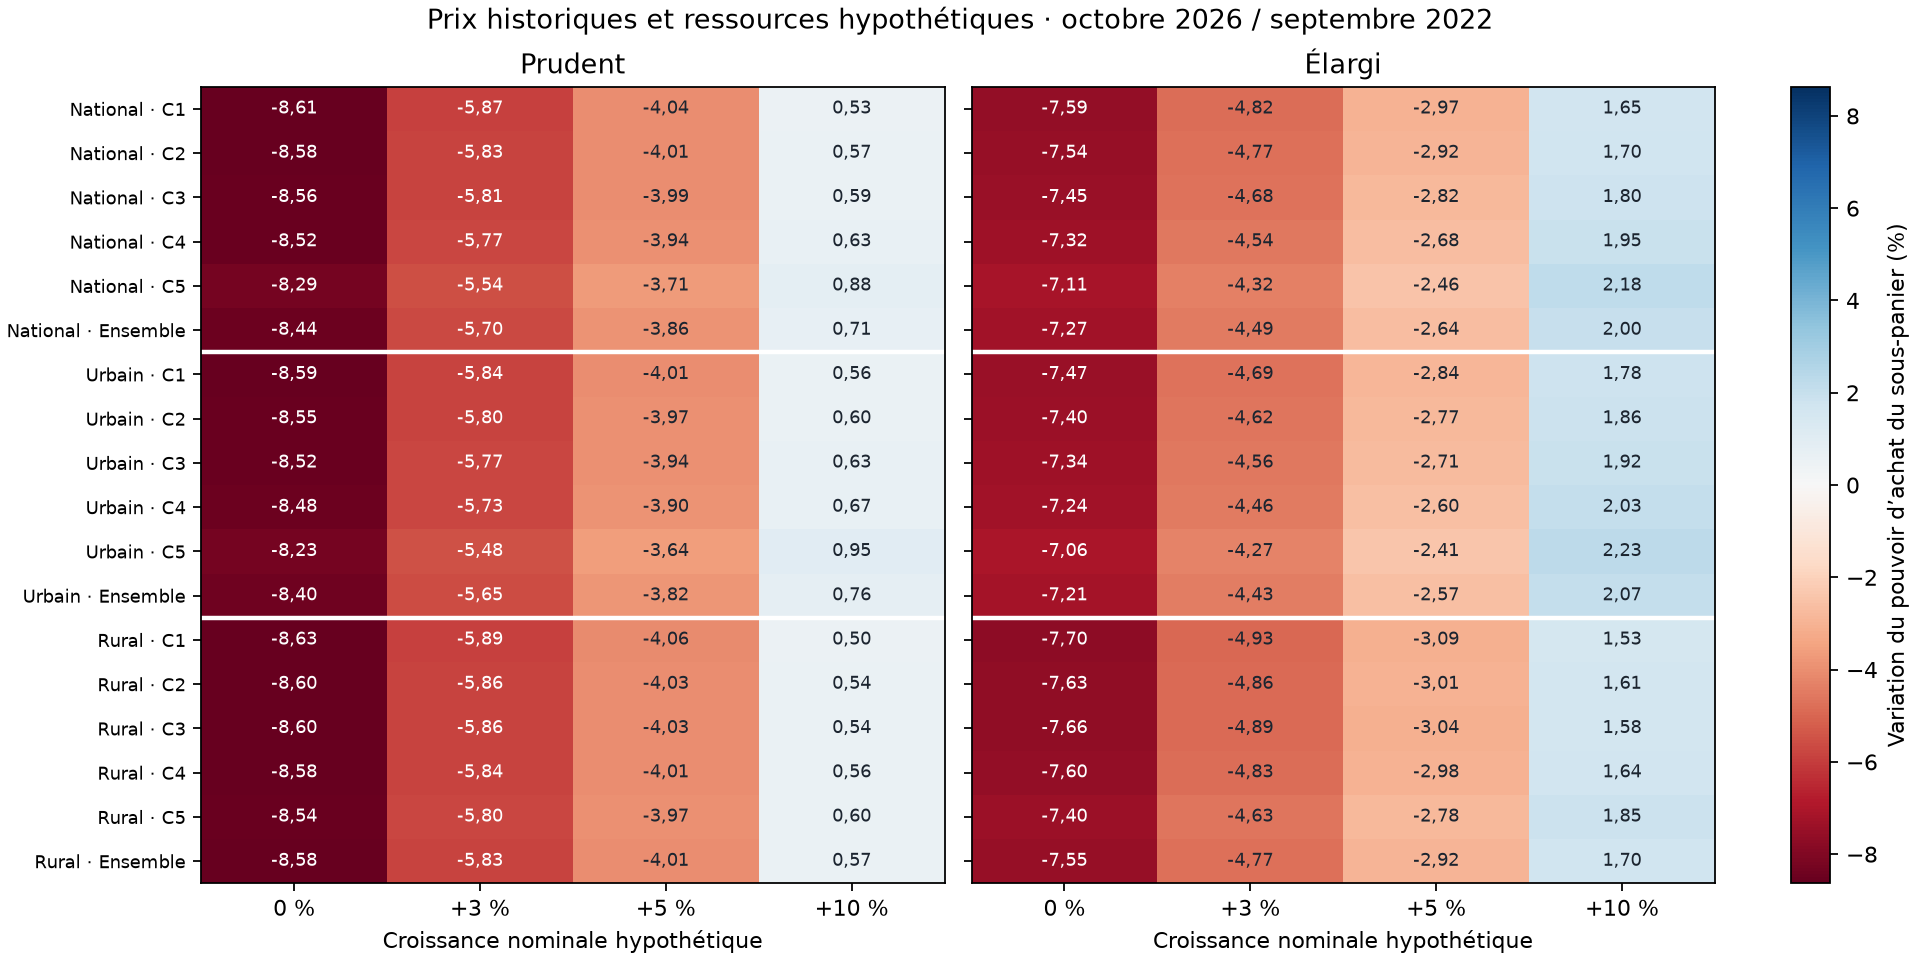

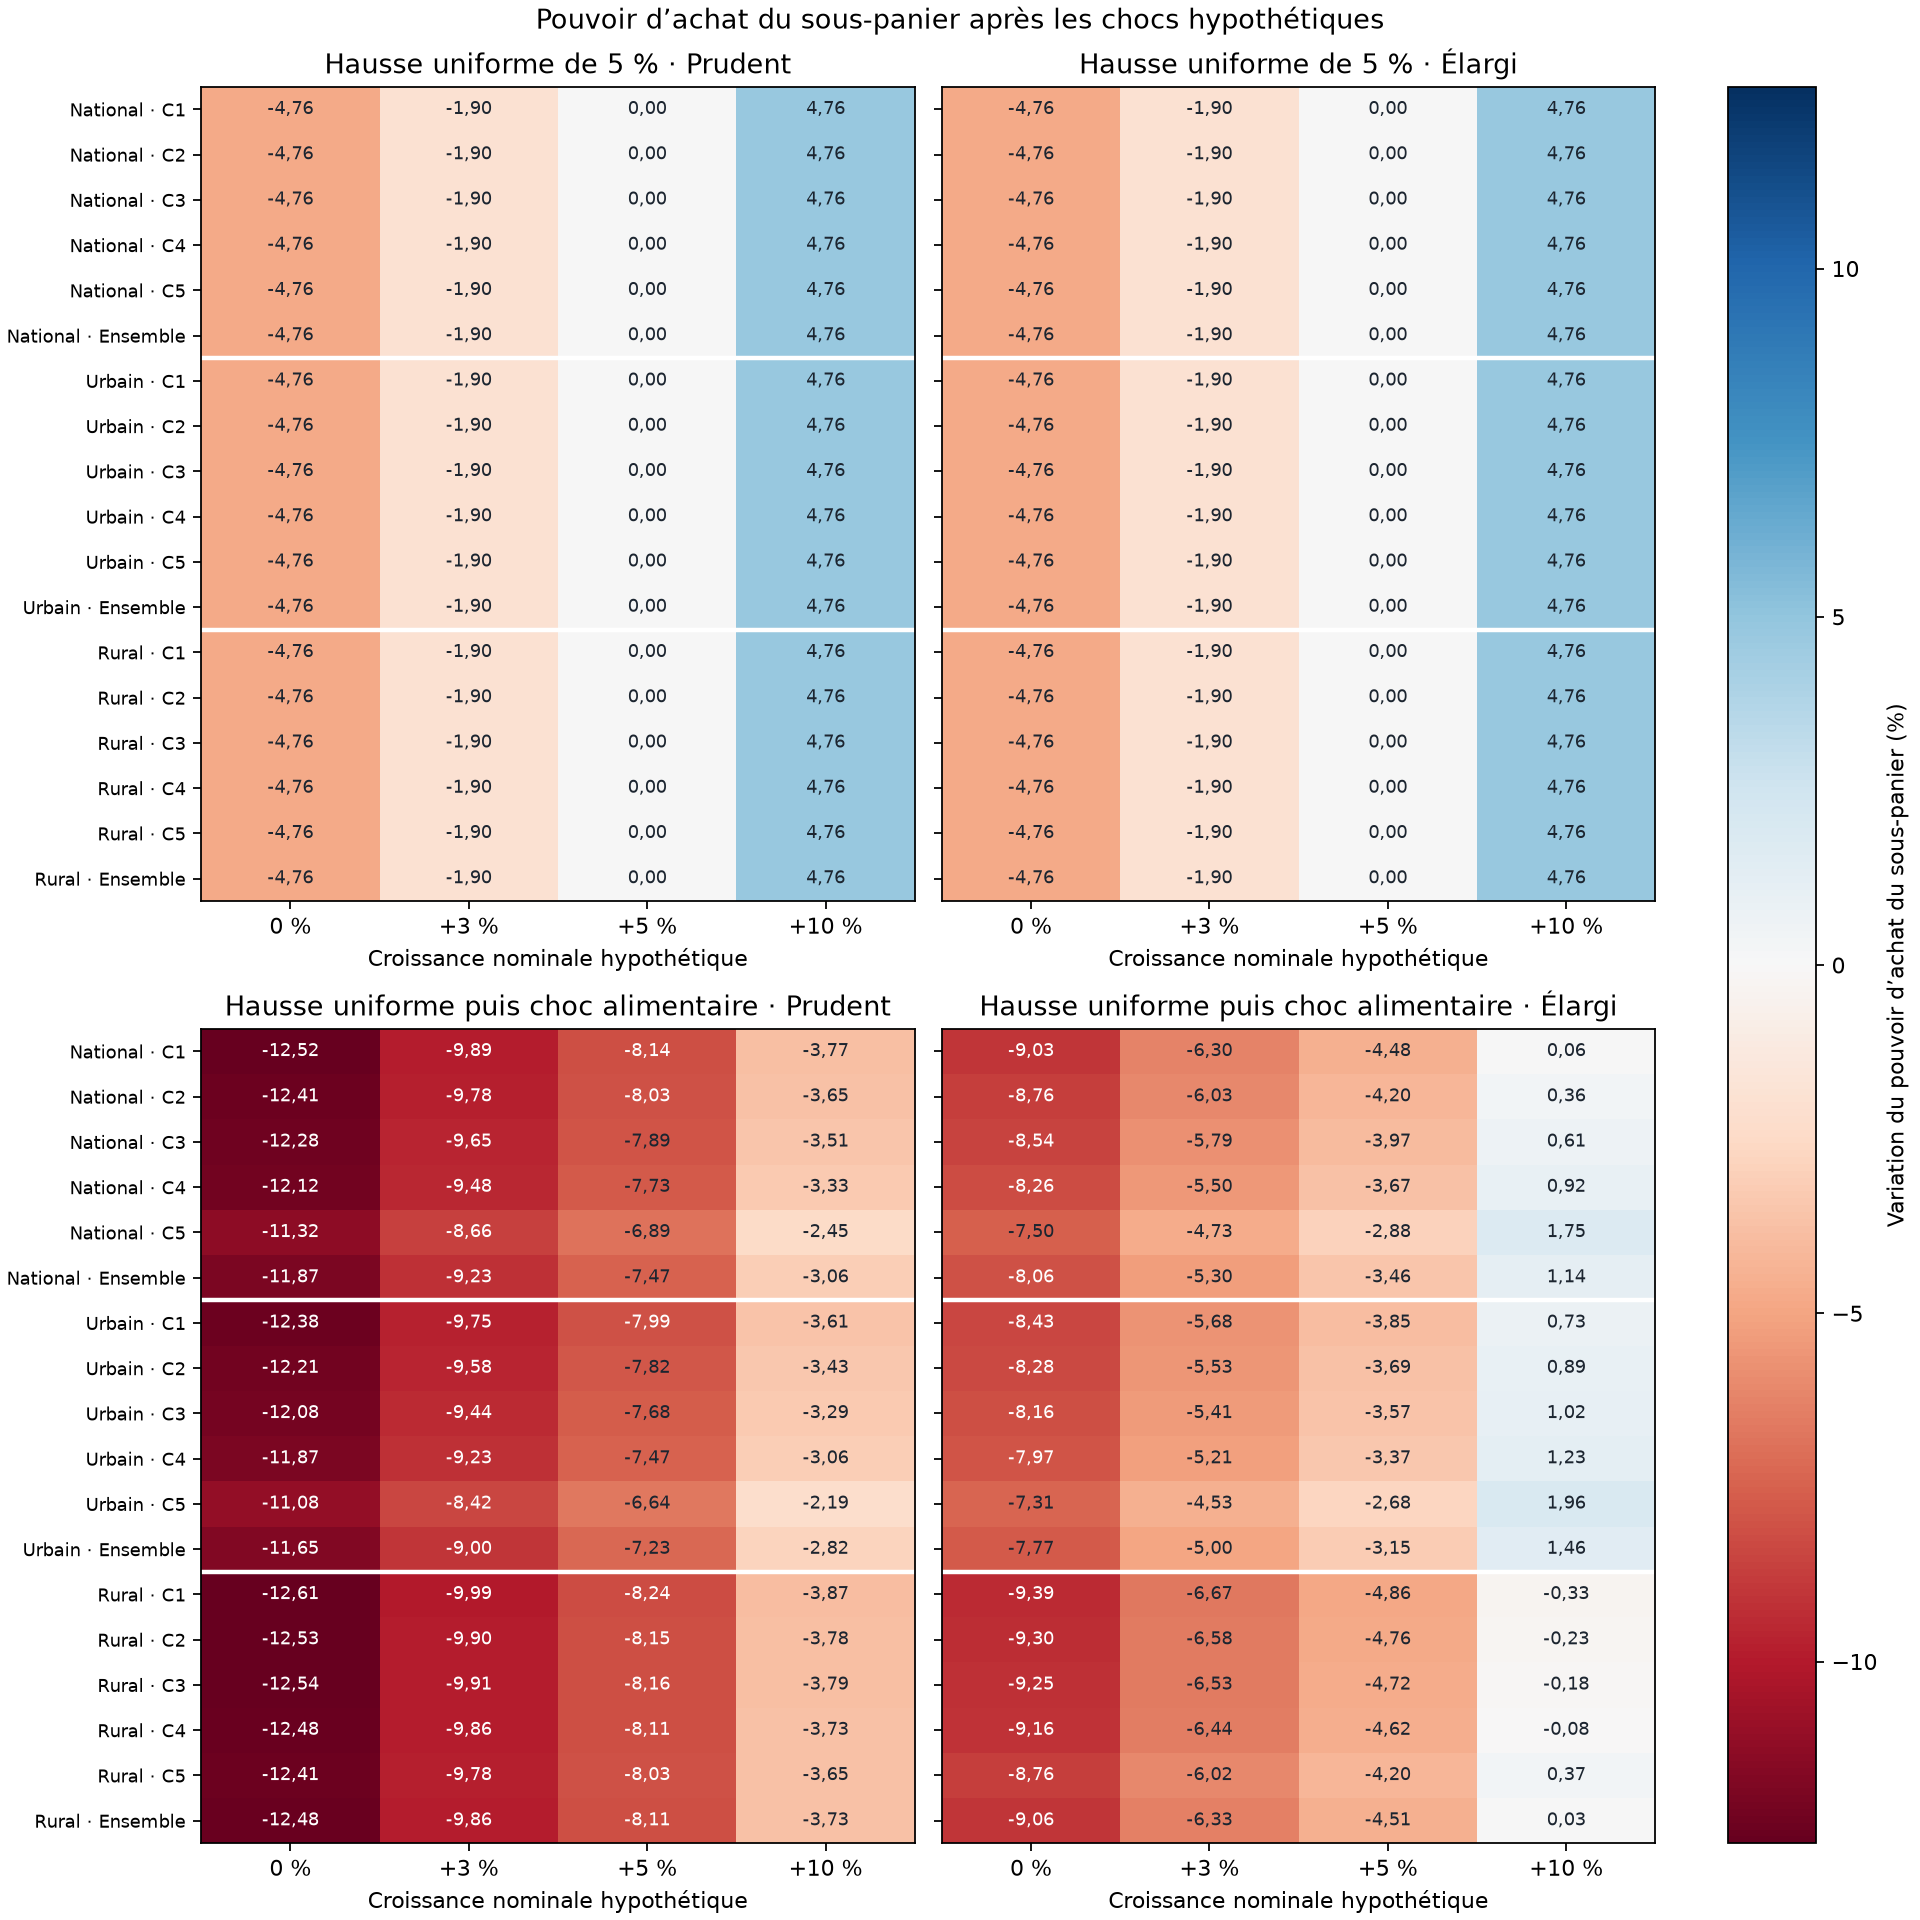

In [4]:
def dessiner_matrices(tableaux, titres, lignes, nom, titre):
    figure, axes = plt.subplots(lignes, 2, figsize=(12, 6 * lignes), sharey=True,
                                layout="constrained")
    limite = max(abs(table[variation]).max() for table in tableaux)
    norme = TwoSlopeNorm(vmin=-limite, vcenter=0, vmax=limite)
    axes_plats = axes.ravel()
    for axe, table, sous_titre in zip(axes_plats, tableaux, titres):
        valeurs = grille(table).to_numpy()
        image = axe.imshow(valeurs, cmap="RdBu", norm=norme, aspect="auto")
        axe.set_title(sous_titre)
        axe.set_xticks(range(len(hypotheses)), [f"+{g} %" if g else "0 %" for g in hypotheses])
        axe.set_yticks(range(len(ordre)), noms_profils, fontsize=8)
        axe.set_xlabel("Croissance nominale hypothétique")
        for i, ligne in enumerate(valeurs):
            for j, v in enumerate(ligne):
                couleur = "white" if abs(v) > 0.63 * limite else "#1c2530"
                explicite = 0.0 if abs(v) < 0.005 else v
                axe.text(j, i, f"{explicite:.2f}".replace(".", ","), ha="center", va="center",
                         color=couleur, fontsize=8)
        for division in (5.5, 11.5):
            axe.axhline(division, color="white", linewidth=2)
    figure.colorbar(image, ax=axes_plats.tolist(), label="Variation du pouvoir d’achat du sous-panier (%)")
    figure.suptitle(titre)
    chemin = sorties / nom
    figure.savefig(chemin, dpi=160)
    plt.close(figure)
    display(Image(filename=str(chemin)))


for nom, table in [
    ("05_pouvoir_achat_historique.csv", resultats_hist),
    ("05_pouvoir_achat_chocs.csv", resultats_chocs),
]:
    table.to_csv(sorties / nom, index=False, encoding="utf-8-sig", float_format="%.8f",
                 date_format="%Y-%m-%d")

titres_perimetres = ["Prudent", "Élargi"]
dessiner_matrices(
    [dernier.loc[dernier["perimetre"].eq(p)] for p in perimetres],
    titres_perimetres, 1, "05_pouvoir_achat_historique.png",
    "Prix historiques et ressources hypothétiques · octobre 2026 / septembre 2022",
)
dessiner_matrices(
    [resultats_chocs.loc[resultats_chocs["perimetre"].eq(p)
                         & resultats_chocs["choc_hypothetique"].eq(c)]
     for c in noms_chocs for p in perimetres],
    [f"{nom} · {p}" for nom in noms_chocs.values() for p in titres_perimetres],
    2, "05_pouvoir_achat_chocs.png", "Pouvoir d’achat du sous-panier après les chocs hypothétiques",
)

## 5. Interprétation économique

Sous un choc uniforme de 5 %, une progression nominale de 5 % maintient exactement le nombre d’unités accessibles pour les 36 couples profil–périmètre. Une hausse de ressources inférieure au taux de coût entraîne une contraction de ce nombre d’unités. L’écart arithmétique entre taux de ressources et taux de coût est une approximation, tandis que le rapport utilisé ici donne la variation exacte.

Sous le choc alimentaire, la sensibilité dépend de la part alimentaire **dans le sous-panier**. Le périmètre prudent et le périmètre élargi ont des compositions et des taux de couverture différents. Leurs résultats décrivent deux objets budgétaires distincts.

Les profils ruraux sont évalués avec les mêmes variations IPC à collecte urbaine. Les écarts simulés reflètent leurs structures de dépenses sous cette hypothèse de prix communs. L’analyse ignore les revenus effectivement observés, les réallocations du budget entre postes, les substitutions et le coût des postes exclus. Ses résultats ne peuvent donc être étendus au pouvoir d’achat du budget total.

In [5]:
def fr(nombre):
    return f"{nombre:.2f}".replace(".", ",")


exemple = dernier.loc[dernier["profil"].eq("National_Total") & dernier[revenu].eq(5)].set_index("perimetre")
texte = []
for p, titre in zip(perimetres, titres_perimetres):
    ligne = exemple.loc[p]
    texte.append(
        f"- **{titre}, ensemble national.** Avec +5 % de ressources, la variation est de "
        f"**{fr(ligne[variation])} %** d’octobre 2026 par rapport à septembre 2022. "
        f"Le seuil nominal est de **{fr(ligne[seuil])} %** pour une couverture "
        f"de {fr(ligne[couverture])} %."
    )
display(Markdown("\n".join(texte)))
combine = resultats_chocs.loc[
    resultats_chocs["choc_hypothetique"].eq("uniforme_5pct_puis_alimentaire_10pct")
    & resultats_chocs[revenu].eq(10)
]
for p, titre in zip(perimetres, titres_perimetres):
    seuils = combine.loc[combine["perimetre"].eq(p), seuil]
    suffisants = int(seuils.le(10).sum())
    display(Markdown(
        f"**Choc combiné · {titre}.** Les seuils vont de {fr(seuils.min())} % à "
        f"{fr(seuils.max())} %. Une hausse nominale de 10 % suffit dans "
        f"**{suffisants} profils sur 18**."
    ))

- **Prudent, ensemble national.** Avec +5 % de ressources, la variation est de **-3,86 %** d’octobre 2026 par rapport à septembre 2022. Le seuil nominal est de **9,22 %** pour une couverture de 41,40 %.
- **Élargi, ensemble national.** Avec +5 % de ressources, la variation est de **-2,64 %** d’octobre 2026 par rapport à septembre 2022. Le seuil nominal est de **7,85 %** pour une couverture de 93,20 %.

**Choc combiné · Prudent.** Les seuils vont de 12,47 % à 14,43 %. Une hausse nominale de 10 % suffit dans **0 profils sur 18**.

**Choc combiné · Élargi.** Les seuils vont de 7,89 % à 10,36 %. Une hausse nominale de 10 % suffit dans **14 profils sur 18**.